# AI-Based University Enquiry Chatbot
### Knowledge Representation + Natural Language Processing
**M.Tech - Fundamentals of Artificial Intelligence · Mini Project (Topic 29)**

| | |
|---|---|
| **Team members** | Manikandan Ayyakkannu (RA2612049015035) · Dinakar B (RA2612049015032) · Manoj Kumar R (RA2612049015005) |
| **Technique** | Frame-based knowledge representation (semantic network) + production rules with forward chaining + an NLP pipeline + a vector-store retrieval fallback |
| **Solution files** | this notebook · `chatbot/` package (Python engine) · `index.html` + `web/` (the chatbot website) · `data/` |
| **Live chatbot** | https://manikandanayyakkannu.github.io/FAI-Mini-Project/ |

**How to run:** open the `university_chatbot` folder in VS Code, choose the Python 3.12 kernel and click **Run All**.
The chatbot itself runs in the browser: open the live link above, with nothing to install.

The notebook follows the nine requirements of the assignment:
1. Problem definition · 2. AI problem formulation · 3. Selection and explanation of the AI technique · 4. Python implementation ·
5. Dataset and test-case preparation · 6. Performance evaluation · 7. Comparison with alternative approaches ·
8. Results, discussion and conclusion · 9. Demonstration of the working prototype

In [1]:
import sys, time, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

sys.path.insert(0, str(Path.cwd()))
from chatbot import UniversityChatbot
from chatbot.knowledge_base import KnowledgeBase, DATA_DIR
from chatbot.nlp import TextPreprocessor, EntityExtractor
from chatbot.reasoning import ReasoningEngine
from chatbot.vector_store import VectorStore
from chatbot.baselines import KeywordFAQBot, RetrievalBot
from chatbot.evaluation import load_test_set, run_bot, summarise, per_category, retrieval_recall_at_k

FIG = Path("docs/figures"); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
COLORS = {"Hybrid KR + NLP (proposed)": "#2a6fdb", "NLP + vector retrieval": "#f2a33a", "Keyword FAQ matching": "#9aa5b1"}
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)

Python 3.12.10 | pandas 3.0.6 | numpy 2.5.4


## 1. Problem Definition

A university answers thousands of repetitive enquiries every year, by phone, e-mail and at many different counters.
Applicants ask *"What is the fee for B.Tech CSE?"* or *"Am I eligible for M.Tech AI with 6.8 CGPA?"*; current students ask
*"When do the end-semester exams start?"*, *"How do I get a bonafide certificate?"* or *"Who should I contact about my hostel room?"*;
alumni ask for transcripts. The answers are spread across the admissions office, the exam cell, the registrar, the accounts office and
the departments, they are not available outside office hours, and they are sometimes inconsistent.

**Goal:** build one intelligent enquiry chatbot for the **whole university** that
* understands free-form English questions, including paraphrases, abbreviations (*B.E*, *M.Tech*, *CGPA*) and spelling mistakes;
* answers factual questions from a structured **knowledge base** of the (fictional) *AI University*: admissions and
  programmes, fees, the academic calendar, exams and results, certificates, university offices, departments, hostel,
  placements, events, research and alumni;
* **reasons** about personal questions, such as eligibility for a programme or the fee after a scholarship, and **explains** each decision;
* keeps track of the **conversation** (follow-up questions such as *"how long is it?"*) and asks for missing details;
* answers free-text FAQs (ragging, Wi-Fi, refunds) through **semantic retrieval**, and politely refuses out-of-scope questions.

**Scope and assumptions:** the knowledge base describes a fictional university, *AI University*, with 20 programmes (engineering,
arts, science, commerce and management), 11 departments, 9 university offices, 7 kinds of certificate, 5 facilities, the
academic calendar, the examination rules, fee payment, events, research, alumni, the admission process and the scholarship policy.
All data is synthetic and created only for this project. The chatbot is text-based, works in English and runs in any web browser.
Anything that is not in the knowledge base (a department the university does not have, or another university) is
answered with a polite "not available" instead of a guess.

## 2. AI Problem Formulation

The chatbot is a **knowledge-based agent**: it perceives a sentence, updates its internal state (the dialogue context),
and acts by choosing and producing the answer that its knowledge base and inference rules support.

**PEAS description**

| PEAS | Description |
|---|---|
| **Performance measure** | correct answers (answer accuracy), correct intent (precision / recall / F1), correct refusal of out-of-scope questions, response time, explainability |
| **Environment** | applicants, parents, current students and alumni typing questions; the university's knowledge (frames, rules, FAQ passages) |
| **Actuators** | text answers, clarification questions, explanation traces |
| **Sensors** | the user's typed sentence |

**Environment properties:** partially observable (the user's intention and facts are hidden and must be inferred from text),
stochastic (the same need can be phrased in many ways), sequential (follow-up questions depend on earlier turns),
static, discrete, single-agent.

**Formulation as knowledge representation and reasoning**

* **Knowledge base (KB):** a set of *frames* `F = {University, Program, UGProgram, PGProgram, btech_cse, ..., hostel, ...}` linked by `is_a` edges.
  Slot lookup uses **inheritance**: `value(f, s) = f.s` if the frame stores the slot; otherwise `value(parent(f), s)`.
* **Percept to query mapping:** NLP maps a sentence *x* to a structured query `q = (intent, entities)`,
  where `intent ∈ {program_fee, eligibility, examination, certificates, office_info, ...}` (27 intents) and the entities are programme, qualification, %, CGPA, exam, category and so on.
* **Working memory (WM):** for a personal question, WM = facts about the programme taken from the frames, plus facts about the applicant taken from the sentence.
* **Rules:** production rules `IF c1 ∧ c2 ∧ ... THEN add fact` (16 eligibility rules and 10 scholarship rules).
* **Inference / goal test:** **forward chaining**. Rules fire until a goal fact (`academic_eligible`, `net_fee`) is derived or no rule can fire.
* **Fallback:** if no intent is confident, the query is embedded as a vector and the closest FAQ passage is retrieved (cosine similarity ≥ threshold);
  otherwise the agent answers "out of scope".

In [2]:
kb = KnowledgeBase()
print(f"Frames: {len(kb.frames)} | Programmes: {len(kb.programs)} | Departments: {len(kb.instances_of('Department'))} "
      f"| Offices: {len(kb.instances_of('Office'))} | Certificates: {len(kb.instances_of('Certificate'))} "
      f"| Facilities: {len(kb.instances_of('Facility'))}")
print("\nis_a chain of 'mtech_ai':", " -> ".join(["mtech_ai"] + kb.ancestors("mtech_ai")))
for slot in ["name", "fee_per_year", "duration", "min_percentage", "application_fee", "phone"]:
    val, src = kb.get_with_source("mtech_ai", slot)
    print(f"  mtech_ai.{slot:<16} = {str(val):<42} (stored in frame: {src})")

Frames: 70 | Programmes: 20 | Departments: 11 | Offices: 9 | Certificates: 7 | Facilities: 5

is_a chain of 'mtech_ai': mtech_ai -> PGProgram -> Program -> University
  mtech_ai.name             = M.Tech Artificial Intelligence             (stored in frame: mtech_ai)
  mtech_ai.fee_per_year     = 120000                                     (stored in frame: mtech_ai)
  mtech_ai.duration         = 2 years (4 semesters)                      (stored in frame: PGProgram)
  mtech_ai.min_percentage   = 60                                         (stored in frame: PGProgram)
  mtech_ai.application_fee  = 1000                                       (stored in frame: Program)
  mtech_ai.phone            = +91 44 2345 6789                           (stored in frame: University)


In [3]:
# The same knowledge seen as a semantic network of (subject, predicate, object) triples
print("Triples with predicate 'offers' (derived inverse of programme.department):")
for t in kb.query(predicate="offers"):
    print("  ", t)
print("\nTotal triples in the semantic network:", len(list(kb.triples())))

Triples with predicate 'offers' (derived inverse of programme.department):
   ('dept_cse', 'offers', 'btech_cse')
   ('dept_aids', 'offers', 'btech_aids')
   ('dept_ece', 'offers', 'btech_ece')
   ('dept_mech', 'offers', 'btech_mech')
   ('dept_mca', 'offers', 'bsc_cs')
   ('dept_mca', 'offers', 'bca')
   ('dept_maths', 'offers', 'bsc_maths')
   ('dept_commerce', 'offers', 'bcom')
   ('dept_mgmt', 'offers', 'bba')
   ('dept_english', 'offers', 'ba_english')
   ('dept_economics', 'offers', 'ba_economics')
   ('dept_aids', 'offers', 'mtech_ai')
   ('dept_aids', 'offers', 'mtech_ds')
   ('dept_mgmt', 'offers', 'mba')
   ('dept_mgmt', 'offers', 'mba_ba')
   ('dept_mgmt', 'offers', 'mba_finance')
   ('dept_mca', 'offers', 'mca')
   ('dept_commerce', 'offers', 'mcom')
   ('dept_english', 'offers', 'ma_english')
   ('dept_research', 'offers', 'phd')

Total triples in the semantic network: 447


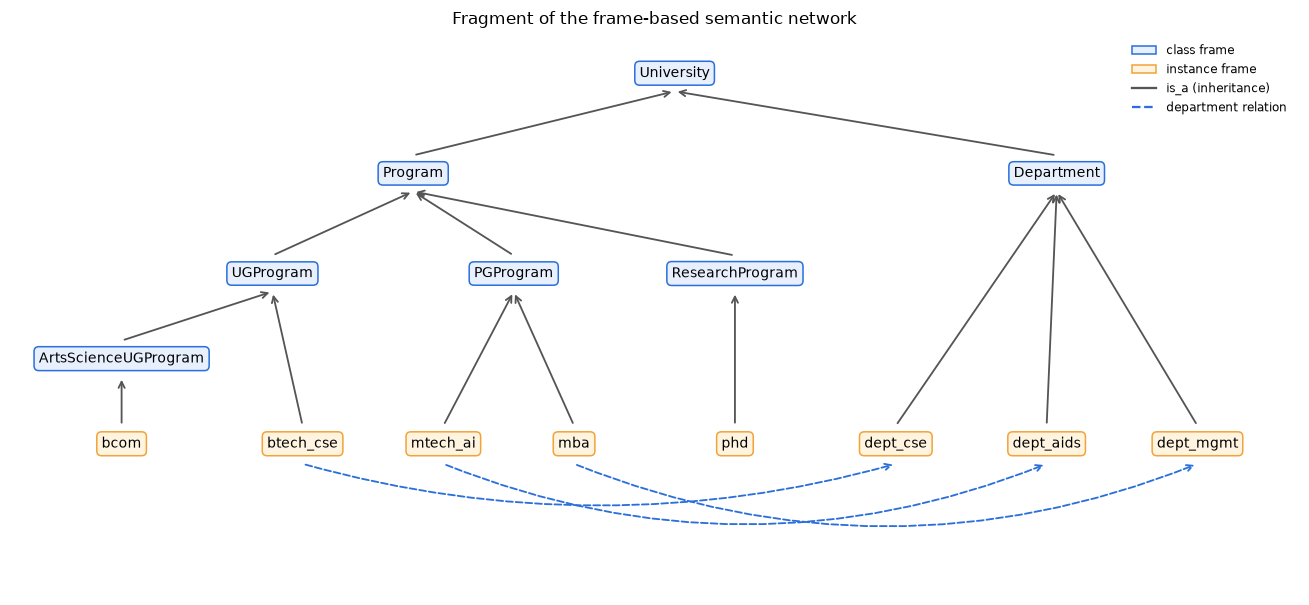

In [4]:
# Draw a small part of the semantic network (is_a and department links)
import matplotlib.patches as mpatches
fig, ax = plt.subplots(figsize=(12, 5.6)); ax.axis("off"); ax.grid(False)
pos = {"University": (5.2, 4), "Program": (2.6, 3), "Department": (9.0, 3),
       "UGProgram": (1.2, 2), "ArtsScienceUGProgram": (-0.3, 1.15), "PGProgram": (3.6, 2), "ResearchProgram": (5.8, 2),
       "btech_cse": (1.5, 0.3), "bcom": (-0.3, 0.3), "mtech_ai": (2.9, 0.3), "mba": (4.2, 0.3), "phd": (5.8, 0.3),
       "dept_cse": (7.4, 0.3), "dept_aids": (8.9, 0.3), "dept_mgmt": (10.4, 0.3)}
curve = {("btech_cse", "dept_cse"): 0.14, ("mtech_ai", "dept_aids"): 0.2, ("mba", "dept_mgmt"): 0.2}
edges = [("Program", "University", "is_a"), ("Department", "University", "is_a"), ("UGProgram", "Program", "is_a"),
         ("ArtsScienceUGProgram", "UGProgram", "is_a"),
         ("PGProgram", "Program", "is_a"), ("ResearchProgram", "Program", "is_a"), ("btech_cse", "UGProgram", "is_a"),
         ("bcom", "ArtsScienceUGProgram", "is_a"), ("mtech_ai", "PGProgram", "is_a"), ("mba", "PGProgram", "is_a"),
         ("phd", "ResearchProgram", "is_a"), ("dept_cse", "Department", "is_a"), ("dept_aids", "Department", "is_a"),
         ("dept_mgmt", "Department", "is_a"),
         ("btech_cse", "dept_cse", "department"), ("mtech_ai", "dept_aids", "department"), ("mba", "dept_mgmt", "department")]
for a, b, lab in edges:
    (x1, y1), (x2, y2) = pos[a], pos[b]
    if lab == "is_a":
        ax.annotate("", xy=(x2, y2 - 0.18), xytext=(x1, y1 + 0.18),
                    arrowprops=dict(arrowstyle="->", color="#555", lw=1.2))
    else:   # department relation drawn as a curve below the instance row
        ax.annotate("", xy=(x2, y2 - 0.2), xytext=(x1, y1 - 0.2),
                    arrowprops=dict(arrowstyle="->", color="#2a6fdb", linestyle="--", lw=1.2,
                                    connectionstyle=f"arc3,rad={curve[(a, b)]}"))
for n, (x, y) in pos.items():
    cls = kb.frames[n].get("type") == "class"
    ax.text(x, y, n, ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.35", fc="#e8f0fe" if cls else "#fff4e0", ec="#2a6fdb" if cls else "#f2a33a"))
ax.legend(handles=[mpatches.Patch(fc="#e8f0fe", ec="#2a6fdb", label="class frame"),
                   mpatches.Patch(fc="#fff4e0", ec="#f2a33a", label="instance frame"),
                   plt.Line2D([], [], color="#555", label="is_a (inheritance)"),
                   plt.Line2D([], [], color="#2a6fdb", ls="--", label="department relation")],
          loc="upper right", fontsize=8, frameon=False)
ax.set_title("Fragment of the frame-based semantic network", fontsize=11)
ax.set_xlim(-1.4, 11.4); ax.set_ylim(-1.2, 4.4)
plt.tight_layout(); plt.savefig(FIG / "fig_semantic_network.png", dpi=150, bbox_inches="tight"); plt.show()

**University-wide knowledge.** Besides admissions, the knowledge base holds frames for the university's offices, the certificates it
issues, the academic calendar, the examination rules, fee payment, events, research and alumni. Inheritance works here too:
every certificate inherits *how to apply* and the issuing office (the Registrar) from the `Certificate` class, and the provisional
certificate overrides the office with the exam cell. The exam dates are not repeated in the `examinations` frame; they are read
from the `academic_calendar` frame.

In [5]:
for cert in ["cert_bonafide", "cert_tc", "cert_provisional"]:
    office, src = kb.get_with_source(cert, "office")
    print(f"{cert:17} office = {office:17} (from frame '{src}')   fee = Rs. {kb.get(cert, 'fee')}, time = {kb.get(cert, 'time')}")
print()
pd.DataFrame([{"office": o, "name": kb.get(o, "name"), "head": kb.get(o, "head"), "phone": kb.get(o, "phone"),
               "handles": kb.get(o, "handles")} for o in kb.instances_of("Office")])

cert_bonafide     office = office_registrar  (from frame 'Certificate')   fee = Rs. 100, time = 1 working day
cert_tc           office = office_registrar  (from frame 'Certificate')   fee = Rs. 0, time = 3 working days
cert_provisional  office = office_coe        (from frame 'cert_provisional')   fee = Rs. 500, time = within 30 days of the final results



,office,name,head,phone,handles
0,office_admissions,Admissions Office,Mr. S. Kumar (Director of Admissions),+91 44 2345 6789,"applications, entrance exams, counselling and seat allotment"
1,office_registrar,Office of the Registrar,Dr. V. Shankar (Registrar),+91 44 2345 6701,"certificates (bonafide, transcript, migration, transfer), student records, ID cards an..."
2,office_coe,Office of the Controller of Examinations (Exam Cell),Dr. L. Prabhu (Controller of Examinations),+91 44 2345 6702,"exam timetables, hall tickets, results, revaluation, supplementary exams and grade sheets"
3,office_accounts,Accounts Office,Mrs. R. Geetha (Finance Officer),+91 44 2345 6703,"fee payment, receipts, refunds, scholarship payments and fee-structure letters for ban..."
4,office_dsw,Office of the Dean of Students (Student Welfare),Dr. P. Meenakshi (Dean of Students),+91 44 2345 6704,"clubs, events, student counselling, grievances, anti-ragging and discipline"
5,office_hostel,Hostel Office,Dr. T. Ravi (Chief Warden),+91 44 2345 6705,"hostel admission, room allotment, mess, and leave and outing permission"
6,office_placement,Training and Placement Cell,Mr. K. Arun Kumar (Placement Officer),+91 44 2345 6706,"campus placements, internships, training and career guidance"
7,office_international,International Relations Office,"Dr. S. Fatima (Director, International Relations)",+91 44 2345 6707,"admission of international students, visas and semester-exchange programmes"
8,office_it,IT Helpdesk,Mr. J. Vimal (IT Manager),+91 44 2345 6708,"student portal login, university e-mail and campus Wi-Fi access"


## 3. Selection and Explanation of the AI Technique

The topic asks for **Knowledge Representation + NLP**. The design combines four classical AI components, each chosen for a reason:

| Component | Technique | Why it was chosen |
|---|---|---|
| **Knowledge representation** | Frames with `is_a` inheritance, which also form a semantic network of triples | University data is naturally hierarchical (Programme → UG/PG → B.Tech CSE). Inheritance avoids repetition: duration, documents and deadlines are stored once at the class level. |
| **Reasoning** | Production rules + **forward chaining** with refraction and an explanation trace | Eligibility and scholarship policies *are* IF-THEN rules. Forward chaining is data-driven: start from the applicant's facts and derive conclusions. Each fired rule becomes a human-readable justification. |
| **NLP** | Normalisation → tokenisation → spelling correction (edit-distance similarity) → synonym mapping → stop-word removal → stemming → regex-based entity extraction → hybrid intent classifier (TF-IDF similarity to examples + keyword evidence) | Transparent and explainable, with no training data beyond 112 example sentences and no internet or GPU needed. It handles abbreviations such as *B.E / B.Tech / M.Tech / CGPA*. |
| **Retrieval fallback** | Vector store with cosine similarity over TF-IDF word and character n-gram embeddings | Free-text FAQ passages (ragging, Wi-Fi, refunds) are not worth modelling as frames. A vector store finds them by similarity of meaning. The embedder is pluggable, so a neural sentence embedding can replace TF-IDF without code changes. |
| **Dialogue management** | Context memory + slot filling | Supports follow-up questions (*"how long is it?"*) and asks for missing facts before reasoning. |
| **Closed-world assumption** | Anything that is not a frame is not offered; a list of known missing departments and other institutions helps recognise such questions | *"HOD of the Civil department?"* gets "not available at AI University", and *"HOD of CSE in SRM?"* gets "I only know AI University", instead of a wrong but confident answer. |

**Why not a pure machine-learning or LLM chatbot?** For admissions, answers must be *exactly* correct (fees, cut-offs), *consistent* and *explainable*.
A knowledge-based system guarantees that every answer is traceable to a frame slot or a rule. An LLM may hallucinate numbers and cannot easily justify an eligibility decision.
The cost of the knowledge-based approach is manual knowledge engineering, which is discussed in Section 8.

### 3.1 NLP pipeline on example sentences

In [6]:
bot = UniversityChatbot()
examples = ["Wat is the fess for B.E Mechanical?",
            "I completed B.E. ECE with 6.8 CGPA, am I eligible for M.Tech AI?",
            "hostle accomodation for girls?",
            "I'm an OBC student with 57% in plus two (PCM). Can I join btech mech?"]
rows = []
for s in examples:
    p = bot.pre.process(s)
    e = bot.extractor.extract(p.normalised)
    intent, conf, _ = bot.classifier.predict(p)
    rows.append({"sentence": s, "normalised": p.normalised, "corrections": p.corrections,
                 "lemmas": " ".join(p.lemmas), "intent": f"{intent} ({conf:.2f})", "entities": e.as_dict()})
pd.DataFrame(rows).T

,0,1,2,3
sentence,Wat is the fess for B.E Mechanical?,"I completed B.E. ECE with 6.8 CGPA, am I eligible for M.Tech AI?",hostle accomodation for girls?,I'm an OBC student with 57% in plus two (PCM). Can I join btech mech?
normalised,wat is the fees for btech mechanical,i completed btech ece with 6.8 cgpa am i eligible for mtech ai,hostel accomodation for girls,i m an obc student with 57 percent in 12th pcm can i join btech mech
corrections,{'fess': 'fees'},{},{'hostle': 'hostel'},{}
lemmas,wat fee btech mechanical,complet btech ece 6.8 cgpa eligibility mtech ai,hostel hostel girl,m obc student 57 percent 12th pcm join btech mech
intent,program_fee (0.69),eligibility (0.86),hostel (0.98),eligibility (0.74)
entities,{'program': 'btech_mech'},"{'program': 'mtech_ai', 'qualification': 'btech_ece', 'cgpa': 6.8}",{'facility': 'hostel'},"{'program': 'btech_mech', 'qualification': '12th', 'percentage': 57.0, 'category': 'ob..."


### 3.2 Intent classification scores (top 4 intents per query)

In [7]:
for s in ["How much does MBA cost?", "Who is the head of the ECE department?", "Is the campus ragging free?"]:
    sc = bot.classifier.scores(bot.pre.process(s))
    top = sorted(sc.items(), key=lambda kv: -kv[1])[:4]
    print(f"{s:42} ->", ", ".join(f"{k}={v:.2f}" for k, v in top))

How much does MBA cost?                    -> program_fee=1.00, scholarship=0.19, fee_payment=0.19, facility=0.16
Who is the head of the ECE department?     -> department_info=0.92, program_fee=0.11, placement=0.09, office_info=0.09
Is the campus ragging free?                -> facility=0.28, events=0.24, program_list=0.02, program_fee=0.01


### 3.3 Forward chaining with an explanation trace

In [8]:
reasoner = ReasoningEngine(kb)
applicant = {"qualification": "btech_ece", "cgpa": 6.8, "exam": "gate", "category": None}
result = reasoner.check_eligibility("mtech_ai", applicant)
print("Rules fired (in order):", [r.rule_id for r in result.fired])
for line in result.explanation_lines():
    print("  ", line)
print("\nDerived facts:", {k: result.facts[k] for k in ["percentage", "required_percentage", "qualification_ok",
                                                         "marks_ok", "academic_eligible", "entrance_ok", "stipend"]})

Rules fired (in order): ['R1', 'R2', 'R4', 'R6', 'R11', 'R12', 'R14', 'R16']
   [R1] Converted CGPA 6.8 to 64.6% using the standard formula (CGPA x 9.5).
   [R2] The minimum required aggregate for M.Tech Artificial Intelligence is 60%.
   [R4] Your qualification (B.Tech ECE) is accepted for M.Tech Artificial Intelligence.
   [R6] Your score 64.6% meets the cut-off of 60%.
   [R11] There is no specific subject requirement for M.Tech Artificial Intelligence.
   [R12] Conclusion: you satisfy the academic eligibility for M.Tech Artificial Intelligence.
   [R14] Your GATE score is accepted for admission.
   [R16] Because you qualified GATE you are eligible for a stipend: Rs. 12,400 per month for GATE-qualified students.

Derived facts: {'percentage': 64.6, 'required_percentage': 60, 'qualification_ok': True, 'marks_ok': True, 'academic_eligible': True, 'entrance_ok': True, 'stipend': True}


In [9]:
# Scholarship reasoning: merit + sports quota, with the cap at 60%
r = reasoner.compute_fee("btech_cse", {"percentage": 96, "sports": True, "sibling": True})
for line in r.explanation_lines():
    print(line)

[S0] The tuition fee for B.Tech Computer Science and Engineering is Rs. 1,50,000 per year.
[S2] Merit scholarship: 96.0% >= 95% gives a 50% tuition waiver.
[S6] Sports quota (state/national level) adds a 25% waiver.
[S7] Sibling concession adds a 10% waiver.
[S8] The total waiver is capped at 60%.
[S9] Net tuition fee = Rs. 1,50,000 - 60% = Rs. 60,000 per year.


### 3.4 Vector-store retrieval (fallback for free-text FAQs)

In [10]:
for q in ["Is there any ragging in the campus?", "Can I get an education loan?", "do students need to wear uniform"]:
    hits = bot.store.search(bot.pre.normalise(q), k=3)
    print(q)
    for h in hits:
        print(f"    {h.score:.2f}  {h.metadata['key']:<28} {h.metadata['question']}")

Is there any ragging in the campus?
    0.53  faq:ragging                  Is the campus ragging free? What is the anti-ragging policy?
    0.25  faq:canteen                  Is there a canteen or food court on campus?
    0.25  faq:medical                  Is there a medical facility or doctor on campus?
Can I get an education loan?
    0.62  faq:education_loan           Can I get an education loan? Does the university help with bank loans?
    0.10  alumni                       Is there an alumni association?
    0.10  certificates:cert_migration  How do I get a migration certificate?
do students need to wear uniform
    0.39  faq:dress_code               Is there a dress code or uniform for students?
    0.32  faq:internship               Do students get internships during the course?
    0.19  office_info:office_dsw       How can I contact the Office of the Dean of Students?


## 4. Python Implementation

The engine is a small Python package, used by this notebook for all the experiments. The chatbot website runs
the **same engine** rewritten in JavaScript (`web/js/`, one file per module) and gives identical answers on all 361 test conversations.

```
university_chatbot/
├── chatbot/
│   ├── knowledge_base.py     frames, inheritance, semantic-network triples
│   ├── nlp.py                normalisation, spelling, synonyms, stemming, entity extraction
│   ├── intent_classifier.py  hybrid TF-IDF similarity + keyword intent classifier
│   ├── reasoning.py          forward-chaining production-rule engine (+ explanations)
│   ├── vector_store.py       in-memory vector store with pluggable embedder
│   ├── answers.py            natural-language answer templates filled from frames
│   ├── faq_builder.py        builds the FAQ corpus (for retrieval and the baselines)
│   ├── engine.py             UniversityChatbot: dialogue manager that ties everything together
│   ├── baselines.py          alternative approaches used for comparison
│   └── evaluation.py         metrics and the test harness
├── data/  knowledge_base.json · rules.json · intents.json · faq_extra.json · test_queries*.csv
├── index.html                the chatbot website
├── web/                      website code (JavaScript version of the engine, styles)
└── tests/engine-test.html    runs the test sets in the browser
```

**Processing pipeline for every message** (`UniversityChatbot.respond`):
1. NLP pre-processing, then entity extraction and intent classification
2. If a task is pending (for example, eligibility is waiting for marks), fill the slot and continue
3. Personal question with facts → **forward chaining** (eligibility or scholarship rules)
4. Dialogue context: resolve *"it"* and elliptical follow-ups (*"what about MBA?"*)
5. Domain gate, and **vector-store retrieval** for unknown or low-confidence questions
6. Otherwise answer from the **frame KB**; return the text plus intent, confidence, source and a full trace

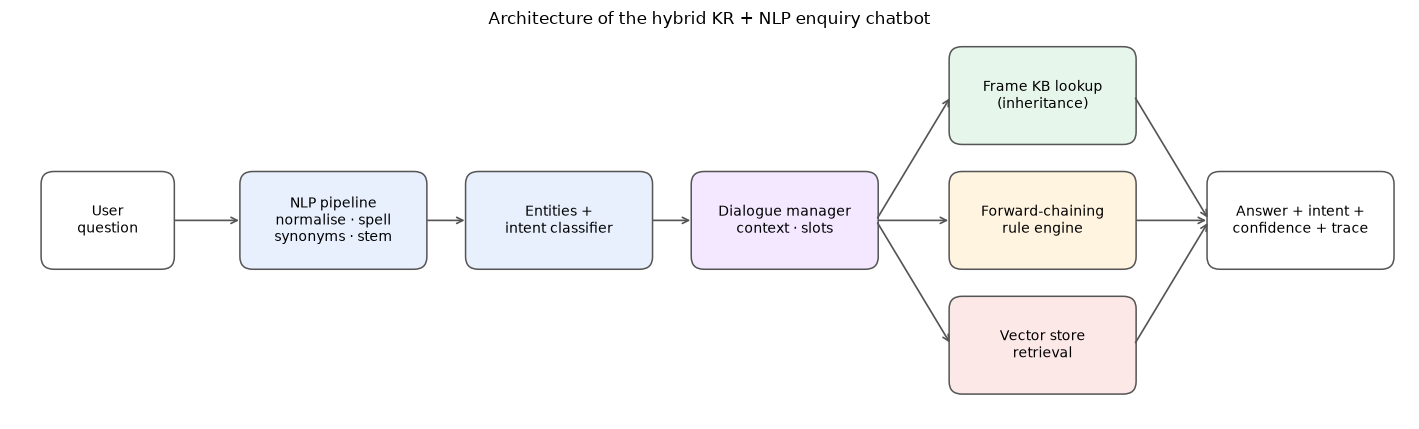

In [11]:
# Architecture diagram
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(13, 4)); ax.axis("off"); ax.grid(False)
W, H = 1.7, 0.9   # box width / height in data units

def box(cx, cy, text, col, w=W):
    ax.add_patch(FancyBboxPatch((cx - w / 2, cy - H / 2), w, H, boxstyle="round,pad=0.02,rounding_size=0.12",
                                fc=col, ec="#555", lw=1))
    ax.text(cx, cy, text, ha="center", va="center", fontsize=9)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color="#555", lw=1.1))

main = [(0.9, "User\nquestion", "#ffffff", 1.2), (3.0, "NLP pipeline\nnormalise · spell\nsynonyms · stem", "#e8f0fe", W),
        (5.1, "Entities +\nintent classifier", "#e8f0fe", W), (7.2, "Dialogue manager\ncontext · slots", "#f3e8ff", W)]
for cx, t, c, w in main:
    box(cx, 1.5, t, c, w)
for (a, _, _, wa), (b, _, _, wb) in zip(main, main[1:]):
    arrow(a + wa / 2, 1.5, b - wb / 2, 1.5)
branches = [(2.7, "Frame KB lookup\n(inheritance)", "#e6f6ea"), (1.5, "Forward-chaining\nrule engine", "#fff4e0"),
            (0.3, "Vector store\nretrieval", "#fde8e8")]
for cy, t, c in branches:
    box(9.6, cy, t, c)
    arrow(7.2 + W / 2, 1.5, 9.6 - W / 2, cy)
    arrow(9.6 + W / 2, cy, 12.0 - W / 2, 1.5)
box(12.0, 1.5, "Answer + intent +\nconfidence + trace", "#ffffff")
ax.set_xlim(0, 13); ax.set_ylim(-0.4, 3.3); ax.set_aspect("auto")
ax.set_title("Architecture of the hybrid KR + NLP enquiry chatbot", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "fig_architecture.png", dpi=150, bbox_inches="tight"); plt.show()

In [12]:
# The rule base (loaded from data/rules.json)
rules = json.load(open(DATA_DIR / "rules.json"))
fmt = lambda c: f"{c['fact']} {c['op']} {c.get('value', c.get('value_fact', ''))}".strip()
pd.DataFrame([{"set": s, "id": r["id"], "name": r["name"], "IF": " AND ".join(fmt(c) for c in r["if"])}
              for s in ("eligibility_rules", "scholarship_rules") for r in rules[s]])

,set,id,name,IF
0,eligibility_rules,R1,CGPA to percentage,cgpa exists AND percentage not_exists
1,eligibility_rules,R2,Base cut-off,min_percentage exists
2,eligibility_rules,R3,Reservation relaxation,"category in ['sc', 'st', 'obc', 'bc', 'mbc'] AND required_percentage exists"
3,eligibility_rules,R4,Qualification accepted,qualification exists AND qualification qual_in allowed_qualifications
4,eligibility_rules,R5,Qualification not accepted,qualification exists AND qualification qual_not_in allowed_qualifications
5,eligibility_rules,R6,Marks meet cut-off,percentage exists AND required_percentage exists AND percentage ge_fact required_perce...
6,eligibility_rules,R7,Marks below cut-off,percentage exists AND required_percentage exists AND percentage lt_fact required_perce...
7,eligibility_rules,R8,Subject requirement met,required_subjects non_empty AND subjects contains_all required_subjects
8,eligibility_rules,R9,Subject requirement unknown,required_subjects non_empty AND subjects not_exists
9,eligibility_rules,R10,Subject requirement not met,required_subjects non_empty AND subjects exists AND subjects not_contains_all required...


In [13]:
# Knowledge base summary: all programmes with inherited slots resolved
pd.DataFrame([{"id": p, "name": kb.get(p, "name"), "level": kb.get(p, "level"), "duration": kb.get(p, "duration"),
               "fee/yr (Rs.)": kb.get(p, "fee_per_year"), "seats": kb.get(p, "seats"),
               "min %": kb.get(p, "min_percentage"), "entrance": ", ".join(kb.get(p, "entrance_exams", []))}
              for p in kb.programs])

,id,name,level,duration,fee/yr (Rs.),seats,min %,entrance
0,btech_cse,B.Tech Computer Science and Engineering,UG,4 years (8 semesters),150000,180,60,"JEE Main, GUET"
1,btech_aids,B.Tech Artificial Intelligence and Data Science,UG,4 years (8 semesters),160000,120,60,"JEE Main, GUET"
2,btech_ece,B.Tech Electronics and Communication Engineering,UG,4 years (8 semesters),130000,120,60,"JEE Main, GUET"
3,btech_mech,B.Tech Mechanical Engineering,UG,4 years (8 semesters),110000,60,60,"JEE Main, GUET"
4,bsc_cs,B.Sc Computer Science,UG,3 years (6 semesters),70000,120,50,GUET
5,bca,BCA (Bachelor of Computer Applications),UG,3 years (6 semesters),65000,120,50,GUET
6,bsc_maths,B.Sc Mathematics,UG,3 years (6 semesters),50000,60,50,GUET
7,bcom,B.Com (Bachelor of Commerce),UG,3 years (6 semesters),60000,180,50,GUET
8,bba,BBA (Bachelor of Business Administration),UG,3 years (6 semesters),75000,120,50,GUET
9,ba_english,B.A. English Literature,UG,3 years (6 semesters),45000,60,45,GUET


## 5. Dataset and Test-Case Preparation

There is no public dataset for this fictional university, so the knowledge and four test sets were prepared:

1. **Knowledge sources** (`data/`): 70 frames, 26 production rules, 27 intents with 178 example sentences,
   and 175 FAQ passages (160 generated from the frames + 15 free-text passages).
2. **Main test set** (`test_queries.csv`, 105 queries): hand-written to be *different* from the intent examples,
   in 8 categories that stress different abilities: direct factual questions, paraphrases, spelling mistakes, reasoning questions,
   multi-turn conversations (5 dialogues, 14 turns), free-text FAQs, out-of-scope questions and small talk.
   Each query is labelled with the expected **intent** and the expected **answer key**
   (e.g. `program_fee:btech_ece`, `eligibility:mtech_ai:yes`). An answer counts as correct only if the key matches exactly.
   For reasoning questions this means the eligibility decision itself must be right.
3. **Held-out test set** (`test_queries_holdout.csv`, 25 queries): written *after* development finished and evaluated once, without any further changes to the system.
   It gives an unbiased estimate, because the main test set was also used to find bugs during development.
4. **University-services development set** (`test_queries_services.csv`, 40 queries): calendar, exams, results, fee payment,
   certificates, offices, research, events, alumni and two short conversations. It was written after these features were built
   and was then used to improve them, so its score is optimistic (the first run, before any changes, scored 72.5 %).
5. **University-services held-out set** (`test_queries_services_holdout.csv`, 20 queries): written *before* that tuning and scored once.

In [14]:
test = load_test_set()
holdout = load_test_set(DATA_DIR / "test_queries_holdout.csv")
services = load_test_set(DATA_DIR / "test_queries_services.csv")
services_ho = load_test_set(DATA_DIR / "test_queries_services_holdout.csv")
summary = pd.DataFrame({"main test set": test.category.value_counts(sort=False),
                        "held-out set": holdout.category.value_counts(sort=False),
                        "services (dev)": services.category.value_counts(sort=False),
                        "services (held-out)": services_ho.category.value_counts(sort=False)}).fillna(0).astype(int)
summary.loc["TOTAL"] = summary.sum()
summary

,main test set,held-out set,services (dev),services (held-out)
category,,,,
alumni,0,0,1,1
calendar,0,0,6,3
certificates,0,0,5,3
conversation,0,0,4,0
events,0,0,3,2
exams,0,0,5,3
factual,20,2,0,0
fees_payment,0,0,4,2
multi_turn,14,3,0,0


In [15]:
test.groupby("category", sort=False).head(2)[["id", "category", "query", "expected_intent", "expected_key"]]

,id,category,query,expected_intent,expected_key
0,F01,factual,What is the fee for B.Tech ECE?,program_fee,program_fee:btech_ece
1,F02,factual,How many seats are there in MBA?,program_seats,program_seats:mba
20,P01,paraphrase,How much does it cost to study mechanical engineering here?,program_fee,program_fee:btech_mech
21,P02,paraphrase,What would I have to pay per year for the MCA course?,program_fee,program_fee:mca
40,T01,typo,wat is the fess for mba,program_fee,program_fee:mba
41,T02,typo,hostel feez,hostel,hostel
50,R01,reasoning,I scored 82% in 12th with PCM. Am I eligible for B.Tech CSE?,eligibility,eligibility:btech_cse:yes
51,R02,reasoning,I got 55% in 12th. Can I join B.Tech ECE?,eligibility,eligibility:btech_ece:no
66,M01,multi_turn,What is the fee for M.Tech AI?,program_fee,program_fee:mtech_ai
67,M02,multi_turn,How many seats does it have?,program_seats,program_seats:mtech_ai


## 6. Performance Evaluation

**Metrics**
* **Answer accuracy:** the share of queries whose answer key matches the expected key (the main metric).
* **Intent accuracy** and **macro precision / recall / F1** over intents: how well the system understands the question type.
* **Out-of-scope precision / recall:** whether the bot refuses the right questions and only those.
* **Recall@k of the vector store** on free-text FAQ questions: is the right passage in the top-k?
* **Latency:** mean response time per query in milliseconds.

In [16]:
hybrid = UniversityChatbot()
res_h = run_bot(hybrid, test)
m = summarise(res_h)
pd.DataFrame({"Hybrid KR + NLP": m}).round(3)

,Hybrid KR + NLP
Answer accuracy,0.943
Intent accuracy,0.943
Intent macro precision,0.954
Intent macro recall,0.968
Intent macro F1,0.957
Out-of-scope precision,0.900
Out-of-scope recall,0.900
Mean latency (ms),3.169


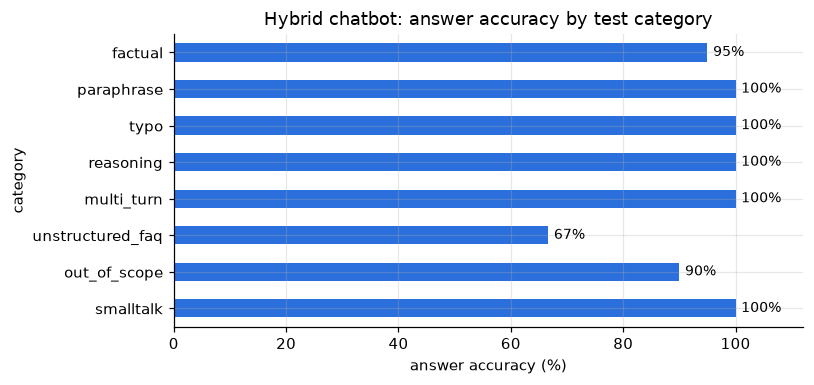

In [17]:
cat_h = per_category(res_h)
ax = (cat_h * 100).plot.barh(figsize=(7.5, 3.6), color="#2a6fdb")
for i, v in enumerate(cat_h * 100):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=9)
ax.set_xlim(0, 112); ax.set_xlabel("answer accuracy (%)"); ax.invert_yaxis()
ax.set_title("Hybrid chatbot: answer accuracy by test category")
plt.tight_layout(); plt.savefig(FIG / "fig_category_hybrid.png", dpi=150, bbox_inches="tight"); plt.show()

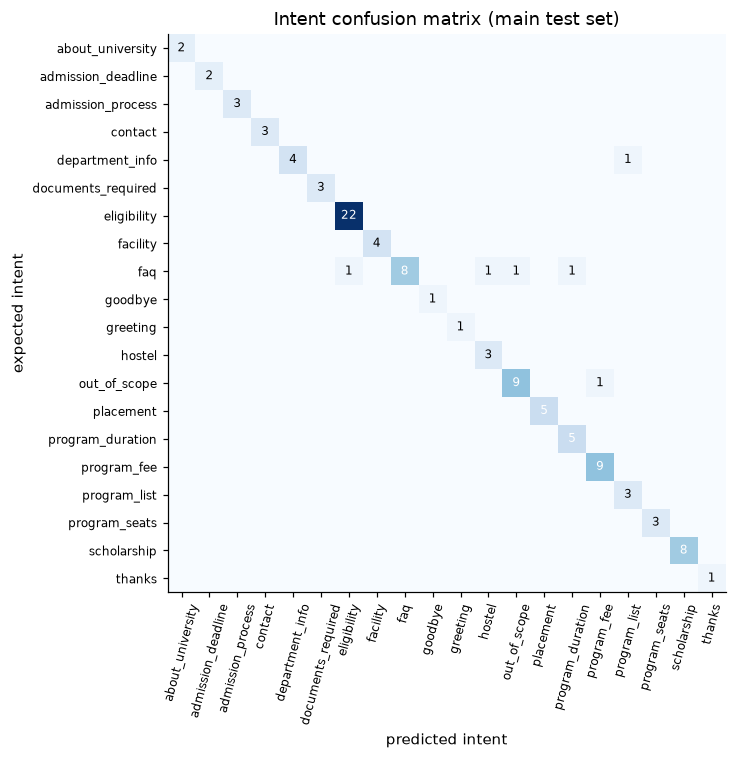

In [18]:
from sklearn.metrics import confusion_matrix
labels = sorted(set(res_h.expected_intent) | set(res_h.pred_intent))
cm = confusion_matrix(res_h.expected_intent, res_h.pred_intent, labels=labels)
fig, ax = plt.subplots(figsize=(8.5, 7)); ax.grid(False)
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(labels)), labels, rotation=75, fontsize=8); ax.set_yticks(range(len(labels)), labels, fontsize=8)
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 4 else "black")
ax.set_xlabel("predicted intent"); ax.set_ylabel("expected intent"); ax.set_title("Intent confusion matrix (main test set)")
plt.tight_layout(); plt.savefig(FIG / "fig_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

In [19]:
print(f"Vector store Recall@1 on free-text FAQ questions: {retrieval_recall_at_k(hybrid.store, hybrid.pre, test, 1):.2f}")
print(f"Vector store Recall@3 on free-text FAQ questions: {retrieval_recall_at_k(hybrid.store, hybrid.pre, test, 3):.2f}")
print(f"Response source mix: {res_h.source.value_counts().to_dict()}")
print(f"Latency: mean {res_h.latency_ms.mean():.2f} ms, 95th percentile {res_h.latency_ms.quantile(.95):.2f} ms, max {res_h.latency_ms.max():.2f} ms")

Vector store Recall@1 on free-text FAQ questions: 0.92
Vector store Recall@3 on free-text FAQ questions: 1.00
Response source mix: {'knowledge_base': 61, 'rule_engine': 19, 'fallback': 10, 'vector_store': 8, 'dialogue': 4, 'smalltalk': 3}
Latency: mean 3.17 ms, 95th percentile 3.93 ms, max 5.54 ms


**Error analysis: every query the hybrid chatbot got wrong**

In [20]:
res_h[~res_h.answer_ok][["id", "category", "query", "expected_key", "pred_key", "source"]]

,id,category,query,expected_key,pred_key,source
17,F18,factual,Which department offers MCA?,department_info:dept_mca,program_list:all,knowledge_base
81,U02,unstructured_faq,Do you have wifi in the hostel?,faq:wifi,hostel,knowledge_base
82,U03,unstructured_faq,Can diploma holders get lateral entry?,faq:lateral_entry,eligibility:ask_program,dialogue
87,U08,unstructured_faq,Do we have to wear a uniform?,faq:dress_code,fallback,fallback
88,U09,unstructured_faq,Can I study abroad for a semester?,faq:exchange,program_duration:all,knowledge_base
98,O07,out_of_scope,What is the share price of Infosys?,fallback,program_fee:all,knowledge_base


## 7. Comparison with Alternative Approaches

Two alternative chatbots were built on **exactly the same knowledge** (the same 152 FAQ question-answer pairs, with identical answer wording),
so that only the *approach* differs:

| System | Description |
|---|---|
| **Keyword FAQ matching** (classic baseline) | raw lower-cased text, word TF-IDF, cosine similarity to FAQ questions. No NLP, no KR, no reasoning, no memory. |
| **NLP + vector retrieval** | the same NLP normalisation and vector store as the hybrid bot, but every answer is retrieved from the FAQ. No frames, rules or dialogue state. |
| **Hybrid KR + NLP (proposed)** | frames + forward chaining + NLP + dialogue manager + vector fallback |

An **ablation study** then removes one component of the hybrid system at a time to measure what each part contributes.

In [21]:
systems = {"Keyword FAQ matching": KeywordFAQBot(), "NLP + vector retrieval": RetrievalBot(),
           "Hybrid KR + NLP (proposed)": hybrid}
results, comp, cats = {}, {}, {}
for name, b in systems.items():
    results[name] = run_bot(b, test)
    comp[name] = summarise(results[name])
    cats[name] = per_category(results[name])
comparison = pd.DataFrame(comp)
comparison.round(3)

,Keyword FAQ matching,NLP + vector retrieval,Hybrid KR + NLP (proposed)
Answer accuracy,0.267,0.324,0.943
Intent accuracy,0.400,0.533,0.943
Intent macro precision,0.457,0.502,0.954
Intent macro recall,0.365,0.416,0.968
Intent macro F1,0.335,0.414,0.957
Out-of-scope precision,0.077,0.185,0.900
Out-of-scope recall,0.100,0.500,0.900
Mean latency (ms),0.437,1.224,3.602


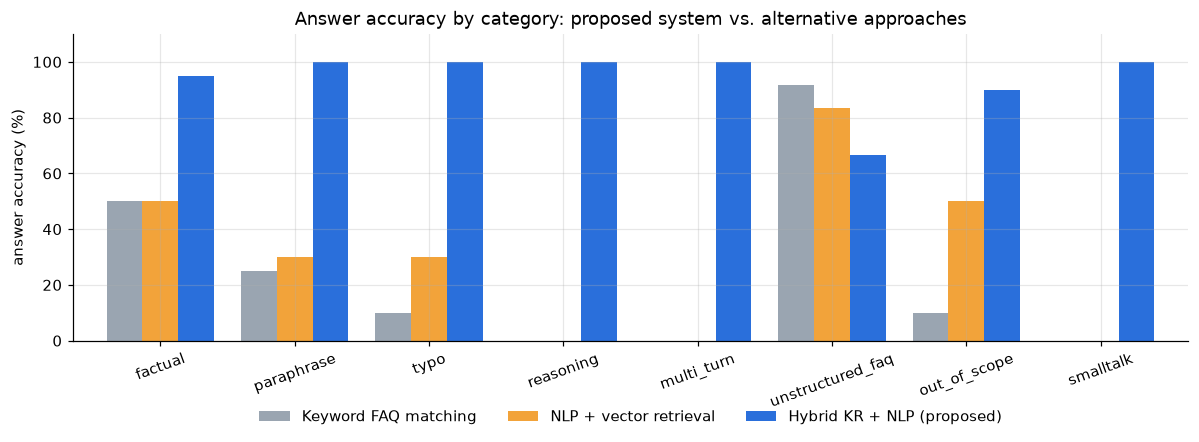

In [22]:
cat_df = pd.DataFrame(cats) * 100
ax = cat_df.plot.bar(figsize=(11, 4.2), width=0.8, color=[COLORS[c] for c in cat_df.columns])
ax.set_ylabel("answer accuracy (%)"); ax.set_ylim(0, 110); ax.set_xlabel("")
ax.set_title("Answer accuracy by category: proposed system vs. alternative approaches")
plt.xticks(rotation=20); ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.tight_layout(); plt.savefig(FIG / "fig_comparison_category.png", dpi=150, bbox_inches="tight"); plt.show()

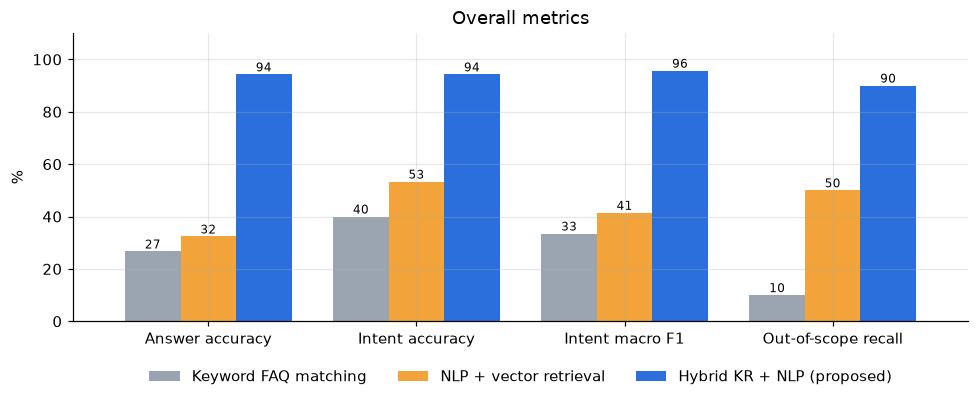

In [23]:
keys = ["Answer accuracy", "Intent accuracy", "Intent macro F1", "Out-of-scope recall"]
ax = (comparison.loc[keys] * 100).plot.bar(figsize=(9, 3.8), width=0.8, color=[COLORS[c] for c in comparison.columns])
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.0f", fontsize=8)
ax.set_ylabel("%"); ax.set_ylim(0, 110); plt.xticks(rotation=0)
ax.set_title("Overall metrics"); ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.savefig(FIG / "fig_comparison_overall.png", dpi=150, bbox_inches="tight"); plt.show()

### 7.1 Ablation study: contribution of each component

In [24]:
ablations = {"Full hybrid": {}, "without reasoning (rules)": {"use_reasoning": False},
             "without dialogue context": {"use_context": False},
             "without spelling correction": {"use_spell_correction": False},
             "without vector-store fallback": {"use_vector_fallback": False}}
abl = {}
for name, kw in ablations.items():
    r = run_bot(UniversityChatbot(**kw), test)
    abl[name] = {"Answer accuracy": r.answer_ok.mean(), **per_category(r).to_dict()}
abl_df = pd.DataFrame(abl).T
abl_df.round(3)

,Answer accuracy,factual,paraphrase,typo,reasoning,multi_turn,unstructured_faq,out_of_scope,smalltalk
Full hybrid,0.943,0.95,1.0,1.0,1.0,1.000,0.667,0.9,1.0
without reasoning (rules),0.743,0.95,1.0,1.0,0.0,0.571,0.750,0.9,1.0
without dialogue context,0.857,0.95,1.0,1.0,1.0,0.357,0.667,0.9,1.0
without spelling correction,0.876,0.95,1.0,0.3,1.0,1.000,0.667,0.9,1.0
without vector-store fallback,0.867,0.95,1.0,1.0,1.0,1.000,0.000,0.9,1.0


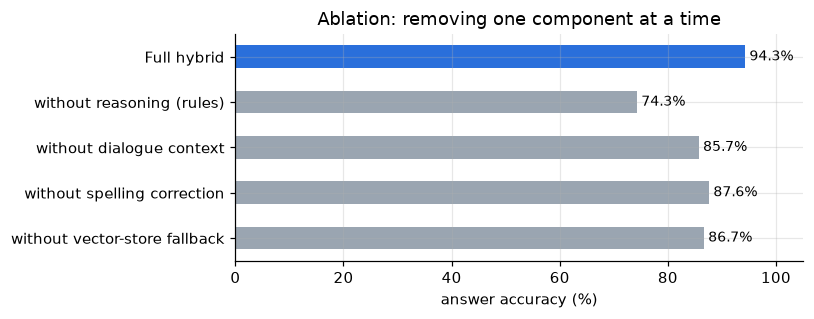

In [25]:
acc = abl_df["Answer accuracy"] * 100
ax = acc.plot.barh(figsize=(7.5, 3), color=["#2a6fdb"] + ["#9aa5b1"] * (len(acc) - 1))
for i, v in enumerate(acc):
    ax.text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, 105); ax.invert_yaxis(); ax.set_xlabel("answer accuracy (%)")
ax.set_title("Ablation: removing one component at a time")
plt.tight_layout(); plt.savefig(FIG / "fig_ablation.png", dpi=150, bbox_inches="tight"); plt.show()

### 7.2 Sensitivity to the intent-confidence threshold

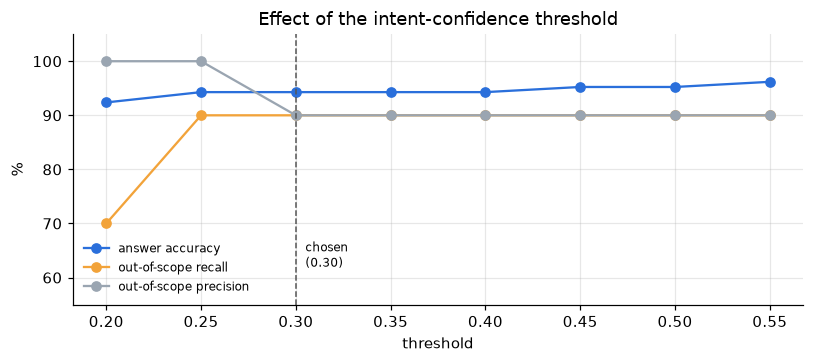

,answer accuracy,out-of-scope recall,out-of-scope precision
threshold,,,
0.20,0.924,0.7,1.0
0.25,0.943,0.9,1.0
0.30,0.943,0.9,0.9
0.35,0.943,0.9,0.9
0.40,0.943,0.9,0.9
0.45,0.952,0.9,0.9
0.50,0.952,0.9,0.9
0.55,0.962,0.9,0.9


In [26]:
sweep = []
for th in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55]:
    s = summarise(run_bot(UniversityChatbot(intent_threshold=th), test))
    sweep.append({"threshold": th, "answer accuracy": s["Answer accuracy"],
                  "out-of-scope recall": s["Out-of-scope recall"], "out-of-scope precision": s["Out-of-scope precision"]})
sweep = pd.DataFrame(sweep).set_index("threshold")
ax = (sweep * 100).plot(marker="o", figsize=(7.5, 3.4), color=["#2a6fdb", "#f2a33a", "#9aa5b1"])
ax.axvline(0.30, ls="--", color="#555", lw=1); ax.text(0.305, 62, "chosen\n(0.30)", fontsize=8)
ax.set_ylabel("%"); ax.set_ylim(55, 105); ax.set_title("Effect of the intent-confidence threshold")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "fig_threshold.png", dpi=150, bbox_inches="tight"); plt.show()
sweep.round(3)

### 7.3 Held-out test set (evaluated once, after development)

*Note: while checking these results one label was found to be wrong (H14: the knowledge base accepts M.Sc Maths, not B.Sc Maths, for M.Tech Data Science, so the chatbot answer "not eligible" was correct). The label was corrected; the system was not changed.*

In [27]:
ho = {}
for name, b in {"Keyword FAQ matching": KeywordFAQBot(), "NLP + vector retrieval": RetrievalBot(),
                "Hybrid KR + NLP (proposed)": UniversityChatbot()}.items():
    r = run_bot(b, holdout)
    ho[name] = summarise(r)
    if name.startswith("Hybrid"):
        ho_errors = r[~r.answer_ok][["id", "query", "expected_key", "pred_key"]]
display(pd.DataFrame(ho).round(3))
ho_errors

,Keyword FAQ matching,NLP + vector retrieval,Hybrid KR + NLP (proposed)
Answer accuracy,0.320,0.480,0.800
Intent accuracy,0.360,0.560,0.800
Intent macro precision,0.273,0.396,0.686
Intent macro recall,0.287,0.396,0.714
Intent macro F1,0.252,0.376,0.670
Out-of-scope precision,1.000,0.333,1.000
Out-of-scope recall,0.333,0.667,0.333
Mean latency (ms),0.448,1.152,3.566


,id,query,expected_key,pred_key
2,H03,Who is in charge of the mechanical department?,department_info:dept_mech,program_fee:btech_mech
7,H08,What papers do I need for the MBA admission?,documents_required:PG,admission_process
21,H22,How are seats allotted during counselling?,faq:counselling,program_seats:all
22,H23,Who is the prime minister of India?,fallback,program_fee:all
24,H25,How to reset my phone password?,fallback,contact


### 7.4 University-services test sets

All three chatbots use the same knowledge here too: the FAQ list is generated from the same frames (one entry for each office,
certificate, the calendar, exams, results, fee payment, events, research and alumni).

*The held-out set scored 80 % for the hybrid chatbot when it was first run. One of its questions ("Can I pay the semester fee using UPI?")
revealed a bug: the spelling corrector turned "using" into "nursing", a word that had been added to the vocabulary for the closed-world
check. The bug was fixed by adding everyday words such as "using" to the list of words that are never corrected; nothing was tuned to
the held-out questions. The numbers below are after that fix.*

In [28]:
sv = {}
for set_name, data in {"services (dev)": services, "services (held-out)": services_ho}.items():
    for name, b in {"Keyword FAQ matching": KeywordFAQBot(), "NLP + vector retrieval": RetrievalBot(),
                    "Hybrid KR + NLP (proposed)": UniversityChatbot()}.items():
        r = run_bot(b, data)
        sv[(set_name, name)] = r.answer_ok.mean()
        if name.startswith("Hybrid") and set_name == "services (held-out)":
            sv_errors = r[~r.answer_ok][["id", "query", "expected_key", "pred_key"]]
display((pd.Series(sv).unstack() * 100).round(1))
sv_errors

,Hybrid KR + NLP (proposed),Keyword FAQ matching,NLP + vector retrieval
services (dev),100.0,42.5,45.0
services (held-out),90.0,40.0,40.0


,id,query,expected_key,pred_key
0,SH01,When does the winter break start?,academic_calendar,admission_deadline:all
2,SH03,What is the lunch break time?,academic_calendar,fallback


## 8. Results, Discussion and Conclusion

### Results
* On the 105-query main (admissions) test set the hybrid KR + NLP chatbot gave the correct answer to **94.3 %** of queries
  (intent macro-F1 **0.96**), against **32.4 %** for NLP + vector retrieval and **26.7 %** for keyword FAQ matching.
* On the **held-out** admissions set it reached **80 %**, against 48 % and 32 %.
  The drop from 94 % to 80 % is the expected optimism of a test set that was also used for debugging; the ranking of the three approaches does not change.
* On the **university-services** questions it reached **100 %** on the development set (72.5 % before it was used for tuning) and
  **90 %** on the held-out set (80 % on the first run, before the spelling bug it revealed was fixed), against 40 % for both alternatives.
* Every answer was produced in about **3 ms** on a laptop CPU, with no GPU and no internet.

### Discussion and observations
1. **Reasoning is what a retrieval bot cannot do.** Both baselines scored **0 %** on reasoning questions and **0 %** on multi-turn questions.
   They can return the *general* eligibility text, but not the *decision* for a specific applicant ("72 % in B.E ECE → eligible for M.Tech AI").
   Removing the rule engine alone drops the hybrid from 94.3 % to 74.3 %, so it is the largest single contributor.
2. **Inheritance keeps the KB small and consistent.** `duration`, `documents` and `deadline` are stored once per class
   (UG/PG/Research) and inherited by all programmes. The trace shows where each value came from (e.g. `mba.duration` comes from `PGProgram`).
3. **Explanations come for free.** Each fired rule produces a sentence, e.g. *"[R1] Converted CGPA 6.8 to 64.6 %"* or *"[R3] 5 % relaxation for OBC"*.
   That transparency matters for admission decisions.
4. **NLP robustness:** spelling correction raised typo accuracy from 30 % to 100 % (ablation), and normalisation of *B.E / B.Tech / M.Tech / plus two / CGPA* was essential for entity extraction.
5. **The vector store complements the KB.** With no fallback, free-text FAQ accuracy is 0 %. With it, 67 %, and Recall@3 is 100 %.
   On those questions the plain retrieval baselines actually score *higher* (83-92 %), because the hybrid sometimes routes a question to a confident KB intent:
   *"wifi in the hostel"* goes to the hostel frame. This is a real trade-off between structured and unstructured knowledge.
6. **Out-of-scope detection** (90 % recall) relies on a domain-vocabulary gate. Questions that share domain words
   (*"share **price** of Infosys"*, where price is a synonym of fee) still slip through. The threshold sweep shows that higher thresholds (0.35-0.55) would score better on this test set (up to 96 %),
   but it was *not* adopted, to avoid tuning on test data. It should be validated on new data first.
7. **One knowledge base for the whole university.** Offices, certificates, the calendar and exam rules are frames like the programmes,
   so new topics needed new frames and answer templates but no new kind of reasoning. Links between frames answer follow-ups such as
   *"Which office handles it?"* (examinations → exam cell). The closed-world assumption keeps the bot honest: a department or another
   university that is not in the knowledge base gets "not available" instead of a confident wrong answer.
8. **Limitations:** the knowledge must be engineered by hand; the rule base covers only eligibility and scholarship policies; the lexical
   TF-IDF embeddings miss pure synonyms (*"in charge of"* vs *"HOD"*); there is English only; and the data is synthetic.

### Conclusion
A hybrid **Knowledge Representation + NLP** chatbot for the whole university was designed, implemented and evaluated. Frames with
inheritance hold the university's structured knowledge: programmes, departments, offices, certificates, the academic calendar and exam rules. Forward-chaining production rules answer personalised eligibility and fee questions with explanations.
A lightweight NLP pipeline turns free-form questions into structured queries, a dialogue manager handles follow-ups and missing details,
and a vector store answers unstructured FAQs. The system clearly beats retrieval-only alternatives, especially on reasoning and multi-turn questions,
while staying fast and explainable, and it runs in any web browser.

**Future work:** replace the TF-IDF embedder with a neural sentence embedding (the `Embedder` interface already supports this);
learn intent weights from real chat logs; add backward chaining for "what do I need to become eligible?" questions; add Tamil/Hindi support;
and connect the KB to the university's live databases (admissions, exam results, fee dues).

## 9. Demonstration of the Working Prototype

### 9.1 Scripted conversation (outputs saved in the notebook)
The conversation below shows factual answers, follow-up questions using context, slot filling, rule-based reasoning,
spelling correction, the vector-store fallback and an out-of-scope refusal.

In [29]:
demo_bot = UniversityChatbot()
session = demo_bot.new_session()
conversation = ["Hi", "What is the fee for M.Tech AI?", "How long is it?", "What about MBA?",
                "Am I eligible for M.Tech AI?", "I did B.E ECE with 6.8 CGPA and I qualified GATE",
                "I scored 96% in 12th and I am a state level athlete. What will my fee be for B.Tech CSE?",
                "hostle fees for girls?", "Is the campus ragging free?", "Who won the cricket match yesterday?", "Thanks, bye"]
for q in conversation:
    r = demo_bot.respond(q, session)
    print(f"YOU : {q}")
    print(f"BOT : {r.text}")
    print(f"      [intent={r.intent} | source={r.source} | confidence={r.confidence:.2f} | {r.latency_ms:.1f} ms]\n")

YOU : Hi
BOT : Hello! I am the AI University enquiry assistant. Ask me anything about the university: admissions and programmes, fees, exams and results, the academic calendar, certificates, offices, hostel, placements or events.
      [intent=greeting | source=smalltalk | confidence=1.00 | 2.0 ms]

YOU : What is the fee for M.Tech AI?
BOT : The tuition fee for M.Tech Artificial Intelligence is Rs. 1,20,000 per year. The total tuition for 2 years is about Rs. 2,40,000. A one-time application fee of Rs. 1,000 and a refundable caution deposit of Rs. 10,000 are also payable. Hostel with mess costs Rs. 85,000 per year extra.
      [intent=program_fee | source=knowledge_base | confidence=0.92 | 3.5 ms]

YOU : How long is it?
BOT : M.Tech Artificial Intelligence is a 2 years (4 semesters) full-time, on campus programme.
      [intent=program_duration | source=knowledge_base | confidence=0.79 | 3.0 ms]

YOU : What about MBA?
BOT : MBA (Master of Business Administration) is a 2 years (4 semest

**University services: exams, an office follow-up, certificates and fees**

In [30]:
s3 = demo_bot.new_session()
for q in ["When are the end semester exams?", "Which office handles it?", "How do I get a bonafide certificate?",
          "What is the late fee for semester fees?", "When does the semester start?", "Who is the VC?"]:
    r = demo_bot.respond(q, s3)
    print(f"YOU : {q}\nBOT : {r.text}\n      [answer key={r.answer_key} | source={r.source}]\n")

YOU : When are the end semester exams?
BOT : End-semester exams: odd semester from 18 November to 5 December 2026; even semester from 28 April to 15 May 2027. The exam timetable is published on the student portal and notice boards three weeks before the exams. For anything else about exams, contact the Office of the Controller of Examinations (Exam Cell).
      [answer key=examination | source=knowledge_base]

YOU : Which office handles it?
BOT : Office of the Controller of Examinations (Exam Cell) - Dr. L. Prabhu (Controller of Examinations). Location: Examination Block. Phone: +91 44 2345 6702, e-mail: coe@aiuniversity.example. Office hours: Monday to Friday, 9:30 AM to 5:30 PM. It handles exam timetables, hall tickets, results, revaluation, supplementary exams and grade sheets.
      [answer key=office_info:office_coe | source=knowledge_base]

YOU : How do I get a bonafide certificate?
BOT : Bonafide certificate: Apply on the student portal (Services > Certificates) or at the Regist

**Explanation trace of the eligibility answer above** (how the answer was produced, step by step):

In [31]:
s2 = demo_bot.new_session()
demo_bot.respond("Am I eligible for M.Tech AI?", s2)
r = demo_bot.respond("I did B.E ECE with 6.8 CGPA and I qualified GATE", s2)
print("\n".join(r.trace))

Normalised text: 'i did btech ece with 6.8 cgpa and i qualified gate'
Lemmas: ['btech', 'ece', '6.8', 'cgpa', 'eligibility', 'gate']
Intent classifier -> eligibility (score 0.68)
Entities: {'qualification': 'btech_ece', 'cgpa': 6.8, 'exam': 'gate'}
Dialogue: continuing pending 'eligibility' task with new facts
Forward chaining fired: R1, R2, R4, R6, R11, R12, R14, R16
[R1] Converted CGPA 6.8 to 64.6% using the standard formula (CGPA x 9.5).
[R2] The minimum required aggregate for M.Tech Artificial Intelligence is 60%.
[R4] Your qualification (B.Tech ECE) is accepted for M.Tech Artificial Intelligence.
[R6] Your score 64.6% meets the cut-off of 60%.
[R11] There is no specific subject requirement for M.Tech Artificial Intelligence.
[R12] Conclusion: you satisfy the academic eligibility for M.Tech Artificial Intelligence.
[R14] Your GATE score is accepted for admission.
[R16] Because you qualified GATE you are eligible for a stipend: Rs. 12,400 per month for GATE-qualified students.


**Questions outside the knowledge base (closed-world assumption).** The AI department has its own HOD. A department the university
does not have, or a question about another university, gets a polite "not available" instead of a wrong answer.

In [32]:
for q in ["Who is the HOD of the AI department?", "Do you have BBA?", "Who is the HOD of the Civil department?",
          "Do you offer Law?", "hi, do you have available seats in medical?", "Who is the HOD of the CSBS department?",
          "Who is the HOD of CSE in SRM University?", "The answers are not relevant"]:
    r = demo_bot.respond(q, demo_bot.new_session())
    print(f"YOU : {q}\nBOT : {r.text}\n      [answer key={r.answer_key} | source={r.source}]\n")

YOU : Who is the HOD of the AI department?
BOT : Department of Artificial Intelligence and Data Science - Head of Department: Dr. N. Kavitha. Located in Turing Block. Email: aids@aiuniversity.example. Programmes offered: B.Tech Artificial Intelligence and Data Science, M.Tech Artificial Intelligence, M.Tech Data Science.
      [answer key=department_info:dept_aids | source=knowledge_base]

YOU : Do you have BBA?
BOT : Yes. BBA (Bachelor of Business Administration) is offered by the School of Management. It is a 3 years (6 semesters) programme with 120 seats, and the tuition fee is Rs. 75,000 per year. Ask me about its eligibility, fees or placements for more details.
      [answer key=program_info:bba | source=knowledge_base]

YOU : Who is the HOD of the Civil department?
BOT : Sorry, the Civil Engineering department is not available at AI University. For more details, please contact the admissions office at +91 44 2345 6789 or admissions@aiuniversity.example.
      [answer key=not_off

### 9.2 The chatbot website
The working chatbot is online at **https://manikandanayyakkannu.github.io/FAI-Mini-Project/**. It runs completely in the browser, on a laptop or a phone, with nothing to install.
The replies contain only the answer; how each one was produced is shown in this notebook (the traces above).
The *Demo 1*, *Demo 2* and *Demo 3* buttons (or `?demo=1`, `?demo=2`, `?demo=3` at the end of the link) play a short sample conversation.

![chatbot website](docs/figures/demo_web_1.png)